# Recorded rockets: DATCOM, RocketPy and measurements

**Work in progress:** DATCOM currently produces poor flight predictions for several comparison rockets. The discrepancies are unresolved and are being investigated; these results should not be treated as validated predictions.

Compare **apogee AGL**, **peak upward vertical velocity**, **CD** and **initial static margin**. Signed measured-reference error is `100 × (prediction − measurement) / |measurement|`; positive means overprediction. Missing data are **—**, never zero. Velocity means the vertical/altimeter ascent channel, not total airspeed. Only five records provide explicit velocity channels. Recorded CD is unavailable; NDRT alone explicitly reports a measured stability margin, with unspecified Mach and loading. Its stability comparison is conditional.

**Apogee-fitted CD is inferred, not measured.** It is one constant coefficient used for both powered and coast drag in the ordinary RocketPy model, fitted to reach the recorded apogee while retaining that source model's mass, atmosphere and lateral aerodynamics. This is one possible effective-loss calibration, not a unique physical CD curve or a DATCOM correction. CD percentages below compare zero-incidence coast CD at Mach 0.6 against that fitted constant; they are not measurement errors. Controlled air-brake cases are not fitted this way.

Both models retain source geometry, motor, mass, atmosphere and launch inputs. DATCOM uses DAMP, powered nozzle-annulus/coast full-base drag and adaptive 20-point Mach grids containing 0.1 and 1.0, with dense transonic points. Signed alpha grids retain at least ±20° and update with the reference trajectory. The ordinary flight seeds actual-atmosphere Reynolds schedules; one DATCOM trajectory update follows. Scope is rail through apogee. Unspecified construction is carbon fibre with vinyl; it supplies no measured roughness or fin section. The untuned comparisons assume smooth 2% HEX sections with 5% bevels and sharp edges; native coefficients are not fitted to apogee.

Source notebook and data hashes, measurement provenance, masks, fitting residuals and availability reasons are saved in `comparison_data/`. Hedy/Valkyrie apogees use archived ordinary outputs where fresh reproduction is unavailable. **AST-HER has not flown** and is compared separately.

**Manual audit:** `comparison_data/datcom_usage_audit.json` records independent guide-example, equivalent-deck and nozzle-sensitivity checks. A corrected `PART` damping-parser bug does not change these saved runs, which omit `PART`. GENESIS and Bella Lui nozzle inputs need hardware verification; full powered base drag still leaves GENESIS 10.5% above its recorded apogee. The source motor radii are not established nozzle measurements. Fin section and finish assumptions remain unverified.

**Fin-section sensitivity:** Additional native runs in `comparison_data/fin_parameter_audit.json` test the unspecified trailing-edge shape. A blunt USER hypothesis gives GENESIS 3025 m and Astra 3378 m, versus recorded 2916 m and 3250 m; a sharp USER control separates the edge effect from HEX/USER method differences. These are unverified geometry assumptions, without fitting, and do not replace the baseline results below.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "rocketpy").is_dir())
DATA = ROOT / "docs/examples/datcom/comparison_data"
plt.rcParams.update({"axes.grid": True, "grid.alpha": .2})
def show(frame):
    display(frame.style.format(precision=3, na_rep="—"))
metrics = pd.read_csv(DATA / "rocket_metrics.csv")
status = pd.read_csv(DATA / "rockets/results.csv")


## Apogee above launch site (m)

In [2]:
show(metrics[metrics.metric == 'Apogee AGL'][['rocket', 'measured', 'rocketpy', 'datcom', 'rocketpy_error_pct', 'datcom_error_pct']])

,rocket,measured,rocketpy,datcom,rocketpy_error_pct,datcom_error_pct
0,andromeda,3443.000,3615.881,4170.733,5.021,21.137
5,astra,3250.000,3043.368,3695.934,-6.358,13.721
10,bella_lui,458.971,460.552,465.877,0.345,1.505
15,camoes,3015.000,3004.104,—,-0.361,—
20,cavour,2789.000,2818.135,3251.609,1.045,16.587
25,defiance,9308.318,9243.891,—,-0.692,—
30,erebus,3020.000,2751.156,3253.423,-8.902,7.729
35,genesis,2916.000,3044.686,3297.239,4.413,13.074
40,halcyon,3450.000,3214.239,3530.232,-6.834,2.326
45,hedy,5231.530,5246.918,—,0.294,—


## Apogee bars and percentage errors

Each panel compares **RocketPy + supplied CD** with **DATCOM**, using the recorded apogee as the dashed black reference. **Green** marks the smaller absolute percentage error; **red** marks the larger error. Grey indicates that the competing result is unavailable, so no winner can be ranked. Panel heights are metres AGL, and each panel has its own vertical scale. Every rocket is retained; missing predictions are labelled, and archived ordinary outputs are identified.

Supplied CD is not universally CFD-derived: Juno III explicitly applies CFD scaling to a RASAero II curve, Cavour identifies RASAero II, and other notebooks supply constants or curves with different/unspecified provenance. RocketPy requires a supplied drag coefficient; there is no separate built-in geometry-to-CD prediction to plot.

Bar labels show signed error `100 × (prediction − recorded) / |recorded|`. The percentile table describes **absolute percentage errors across the same paired rockets**, not per-flight uncertainty or Monte Carlo confidence intervals. The example loader preserves post-construction drag edits in the solver's seven-input coefficient, including Juno's CFD scaling and Bella Lui's updated curve.

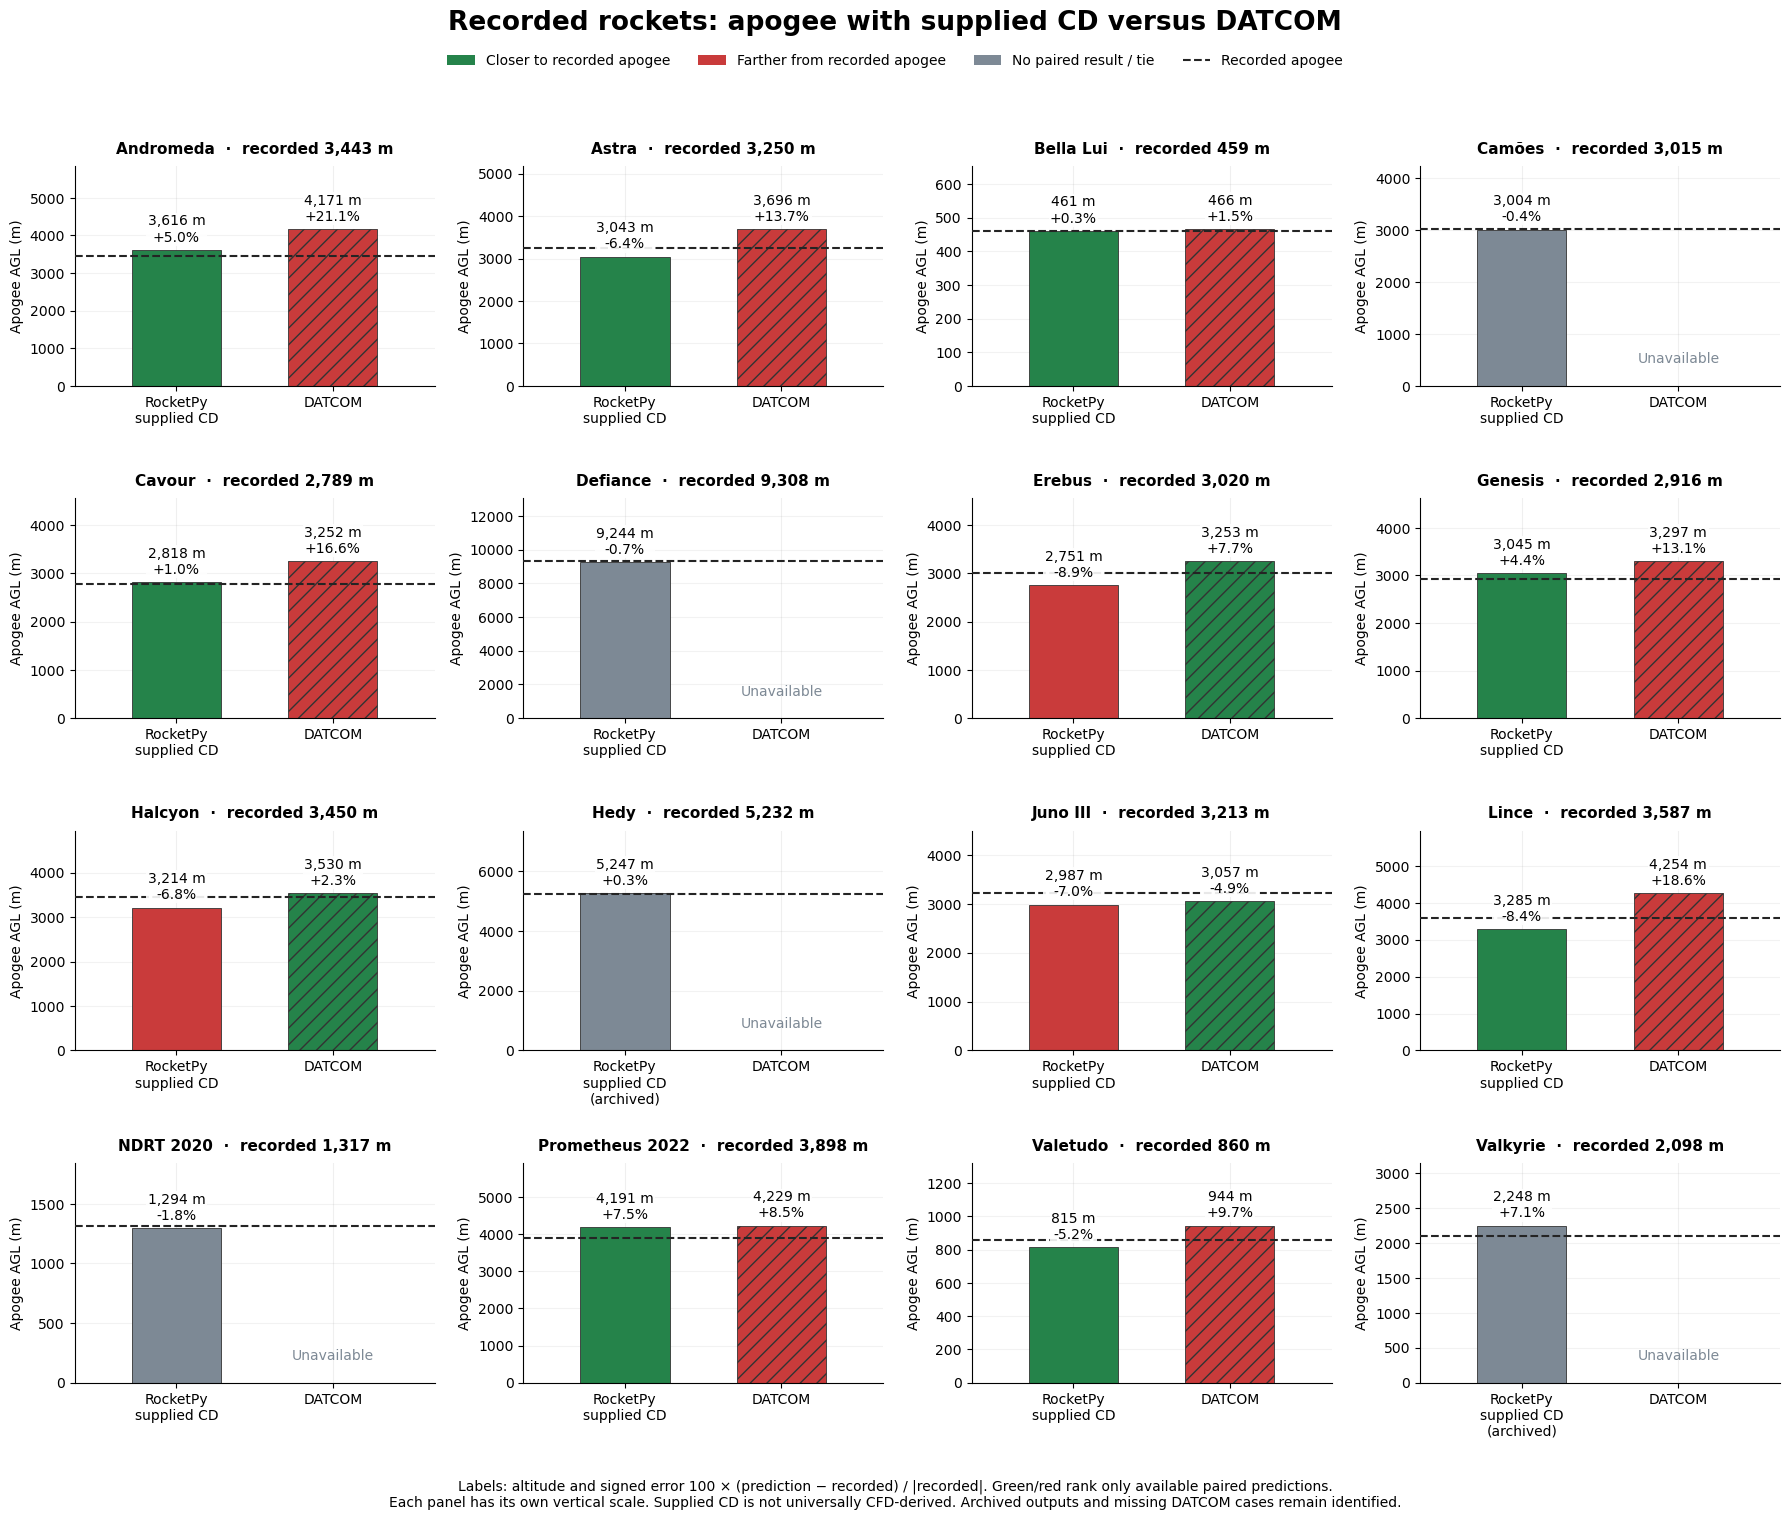

,Model,Paired rockets,P50 (%),P75 (%),P90 (%),P95 (%)
0,RocketPy + supplied CD,11,6.358,7.270,8.417,8.659
1,DATCOM,11,9.723,15.154,18.603,19.870


,rocket,drag_provenance,closer_prediction
0,andromeda,Supplied CD; CFD provenance not established,RocketPy + supplied CD
1,astra,Supplied CD; CFD provenance not established,RocketPy + supplied CD
2,bella_lui,Supplied CD; CFD provenance not established,RocketPy + supplied CD
3,camoes,Supplied CD; CFD provenance not established,unavailable comparison
4,cavour,RASAero II (source cell 10),RocketPy + supplied CD
5,defiance,Supplied CD; CFD provenance not established,unavailable comparison
6,erebus,Supplied CD; CFD provenance not established,DATCOM
7,genesis,Supplied CD; CFD provenance not established,RocketPy + supplied CD
8,halcyon,Supplied CD; CFD provenance not established,DATCOM
9,hedy,Supplied CD; CFD provenance not established,unavailable comparison


In [3]:
import sys
sys.path.insert(0, str(DATA))
from plot_apogee_comparison import comparison_data, error_percentiles, plot_apogees, save_apogees

apogee_bars = comparison_data(DATA)
apogee_bars.to_csv(DATA / "apogee_comparison.csv", index=False)
fig = plot_apogees(apogee_bars)
save_apogees(fig, DATA)
plt.show()
plt.close(fig)

percentiles = error_percentiles(apogee_bars)
percentiles.to_csv(DATA / "apogee_error_percentiles.csv", index=False)
show(percentiles.rename(columns={"model": "Model", "paired_rockets": "Paired rockets", **{f"P{p}_absolute_error_pct": f"P{p} (%)" for p in [50, 75, 90, 95]}}))
show(apogee_bars[["rocket", "drag_provenance", "closer_prediction"]])
assert set(apogee_bars.rocket) == set(status.rocket)
assert (apogee_bars.measured > 0).all()

## DATCOM sensitivity bars versus recorded apogees

The current engineering rule uses **at least ±20% static CD at every Mach/AoA**, with **±2% of nose-to-CP distance**. Larger native-relative axial-force discrepancies from Wu et al. are retained as a CD-error proxy **inside Mach 0.8–3.02 and alpha ±6°**. Outside that envelope use 20%. This replaces the earlier independent CN/CM-alpha variations. At finite incidence, the added drag follows the airflow and preserves perpendicular force; static moments are transferred consistently and native damping is retained.

Compare **RocketPy + supplied CD**, **nominal DATCOM with asymmetric scenario whiskers**, and the **recorded apogee** (dashed line). Whiskers span nominal and the upper/lower drag-and-CP scenarios; they are **not confidence intervals**. Green/red rank nominal errors. The scenarios correlate drag and CP and do not exhaust independent combinations.

The design-accuracy discussion is referenced to **J. T. White (1995), AIAA 95-1893**, [doi:10.2514/6.1995-1893](https://doi.org/10.2514/6.1995-1893). White studies supersonic **CN/CP** accuracy and cites criteria based on CN and CP/body length; he does **not** establish universal 20% CD or 2% nose-to-CP uncertainty. Applying these values throughout flight is an explicit engineering assumption. The larger in-envelope errors adapt Wu et al. (2019), [doi:10.1088/1757-899X/612/3/032096](https://doi.org/10.1088/1757-899X/612/3/032096), Table 2 (CC BY 3.0). Measurement-relative errors are converted to native-relative magnitudes before use.

Sensitivity runs now cover **all 11 currently supported recorded-rocket DATCOM models**. Recorded apogees fall inside the ranges for **4/11**; RocketPy's supplied-CD nominal prediction is closer for **8/11**. These counts do not establish a confidence level. The original chart above retains all 16 rockets and identifies unavailable cases.

Values are metres AGL. Supplied CD is not universally CFD-derived. Rendering uses saved outputs and requires no native executable runs.

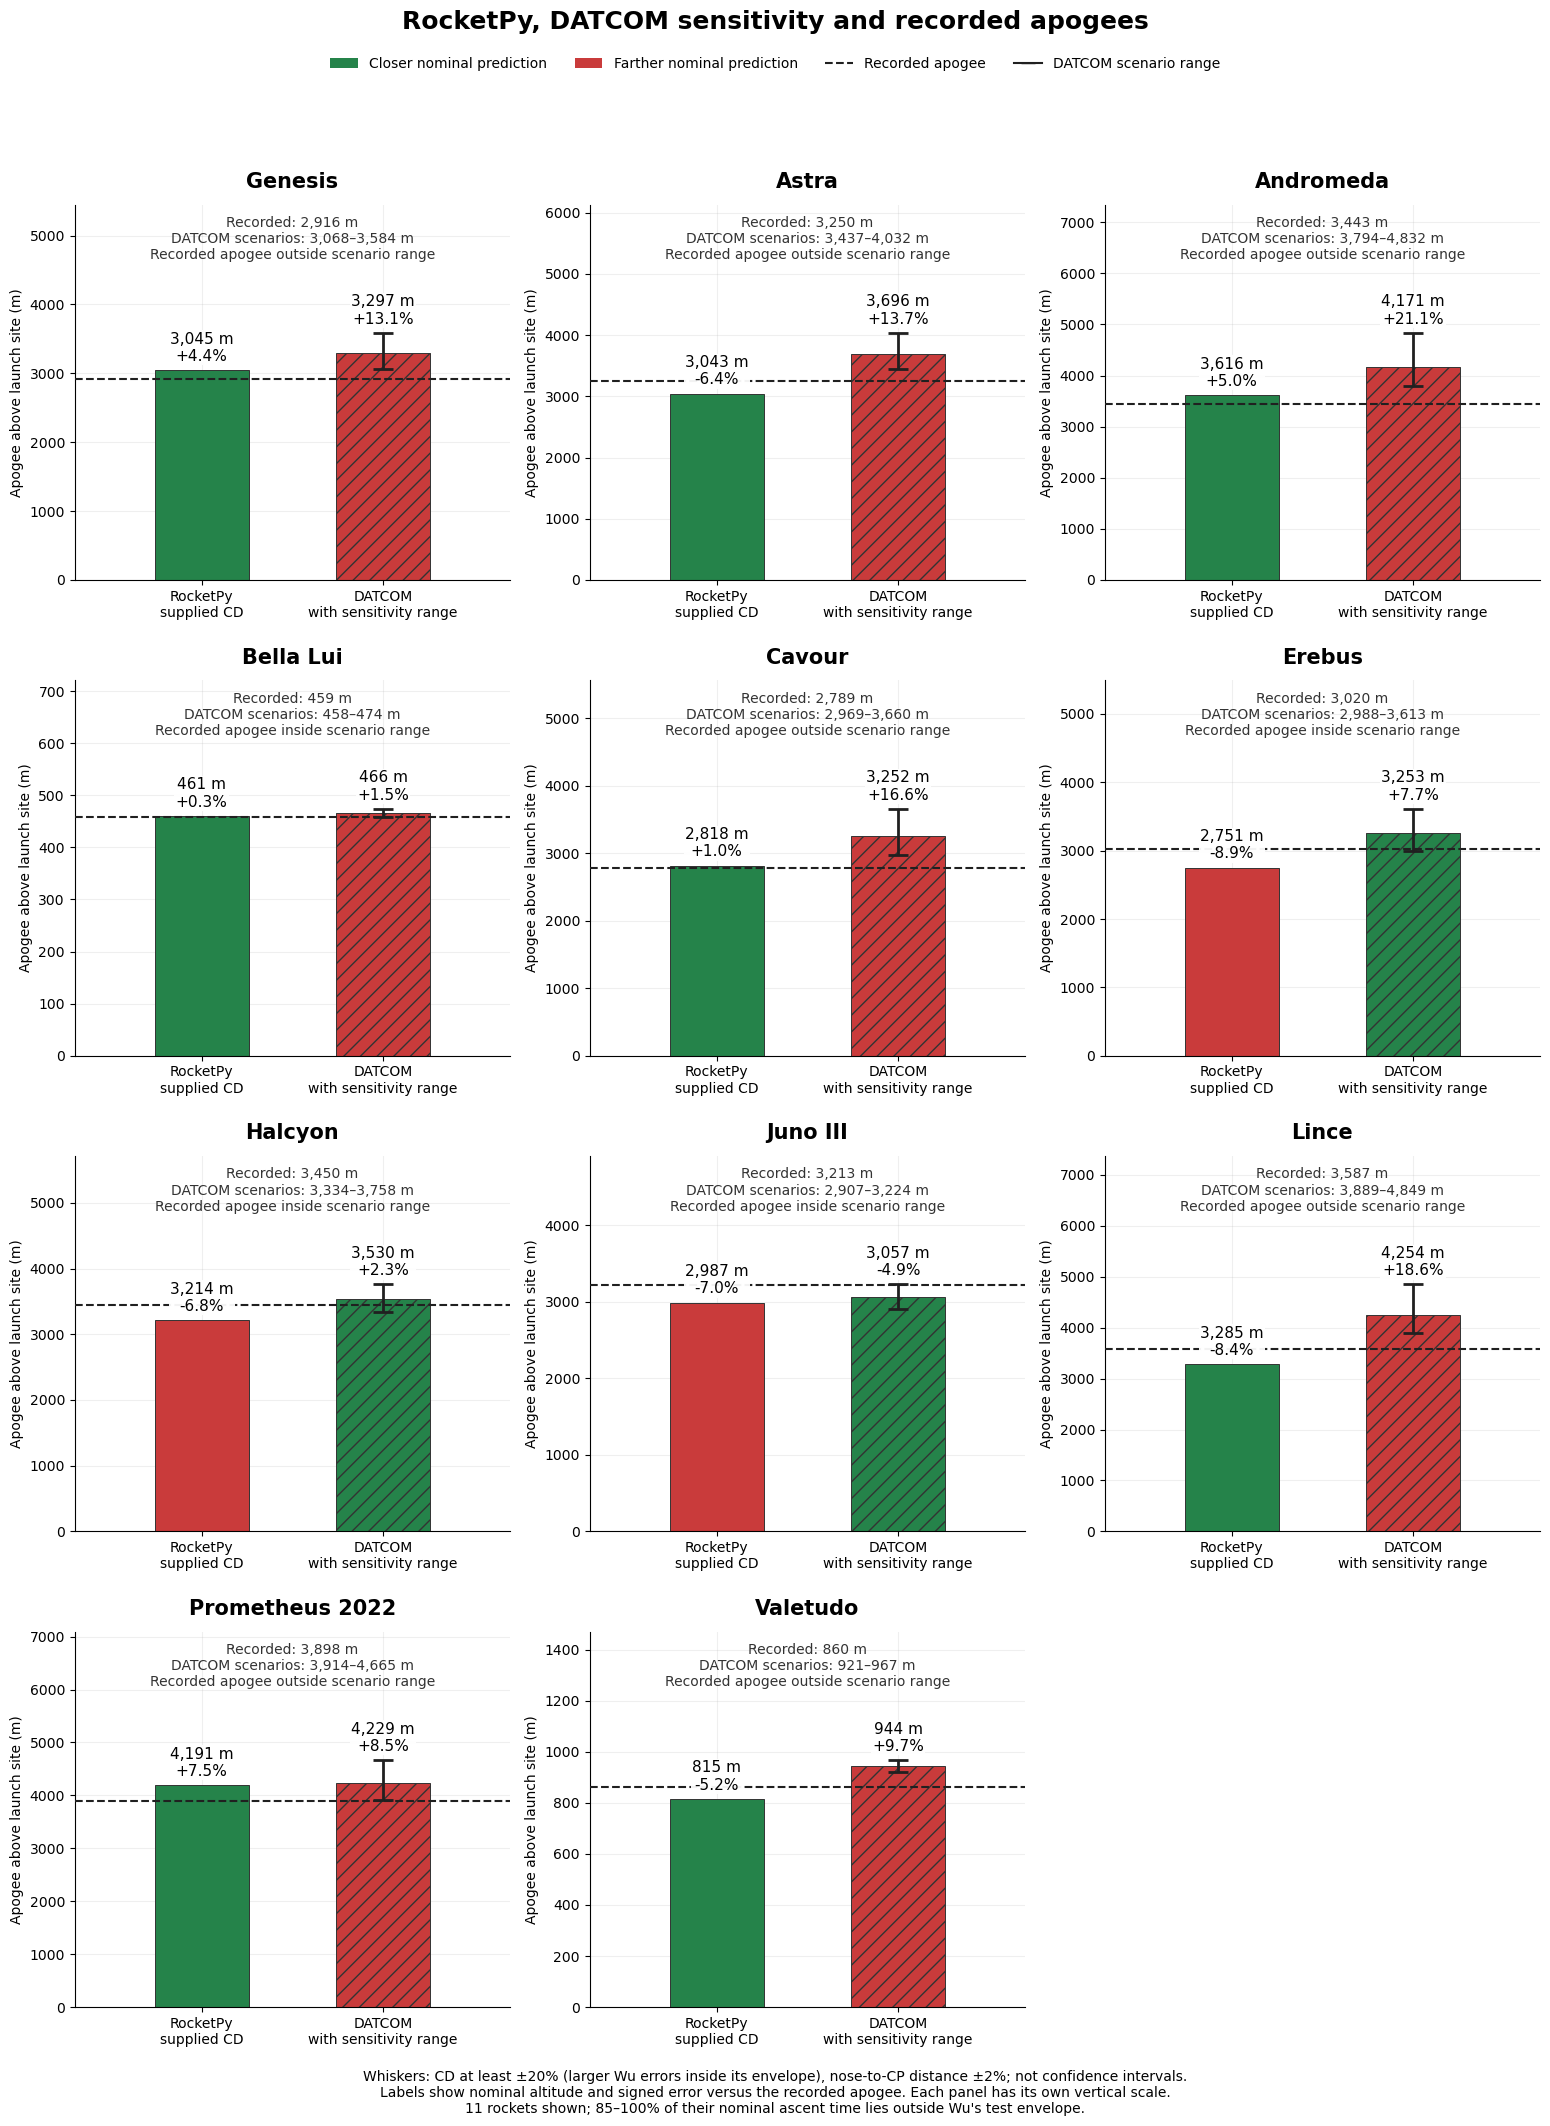

,Rocket,Recorded (m),RocketPy (m),RocketPy error (%),DATCOM (m),DATCOM error (%),DATCOM range (m),Range error (%),Recorded in range
0,genesis,2916.000,3044.686,4.413,3297.239,13.074,"3,067.9–3,584.4",+5.2 to +22.9,No
1,astra,3250.000,3043.368,-6.358,3695.934,13.721,"3,436.9–4,031.7",+5.8 to +24.1,No
2,andromeda,3443.000,3615.881,5.021,4170.733,21.137,"3,793.8–4,831.9",+10.2 to +40.3,No
3,bella_lui,458.971,460.552,0.345,465.877,1.505,457.8–474.2,-0.3 to +3.3,Yes
4,cavour,2789.000,2818.135,1.045,3251.609,16.587,"2,968.7–3,660.2",+6.4 to +31.2,No
5,erebus,3020.000,2751.156,-8.902,3253.423,7.729,"2,988.0–3,613.0",-1.1 to +19.6,Yes
6,halcyon,3450.000,3214.239,-6.834,3530.232,2.326,"3,334.2–3,757.6",-3.4 to +8.9,Yes
7,juno3,3213.000,2987.281,-7.025,3056.550,-4.869,"2,907.2–3,223.8",-9.5 to +0.3,Yes
8,lince,3587.000,3285.089,-8.417,4254.304,18.603,"3,889.1–4,849.0",+8.4 to +35.2,No
9,prometheus_2022,3898.370,4191.289,7.514,4229.197,8.486,"3,914.0–4,665.2",+0.4 to +19.7,No


In [9]:
from plot_apogee_uncertainty import (
    uncertainty_comparison,
    plot_uncertainty_comparison,
    save_uncertainty_comparison,
)

uncertainty = uncertainty_comparison(DATA)
uncertainty.to_csv(DATA / "apogee_uncertainty_comparison.csv", index=False)
fig = plot_uncertainty_comparison(uncertainty)
save_uncertainty_comparison(fig, DATA)
plt.show()
plt.close(fig)

summary = uncertainty[["rocket", "measured", "rocketpy", "rocketpy_error_pct", "datcom", "datcom_error_pct"]].rename(columns={
    "rocket": "Rocket", "measured": "Recorded (m)",
    "rocketpy": "RocketPy (m)", "rocketpy_error_pct": "RocketPy error (%)",
    "datcom": "DATCOM (m)", "datcom_error_pct": "DATCOM error (%)",
})
summary["DATCOM range (m)"] = uncertainty.apply(
    lambda row: f"{row.datcom_scenario_low_m:,.1f}–{row.datcom_scenario_high_m:,.1f}", axis=1
)
summary["Range error (%)"] = uncertainty.apply(
    lambda row: f"{row.datcom_low_error_pct:+.1f} to {row.datcom_high_error_pct:+.1f}", axis=1
)
summary["Recorded in range"] = uncertainty.recorded_within_datcom_scenarios.map({True: "Yes", False: "No"})
show(summary)


## Stability sensitivity from the ±2% CP rule

The CP shift is **2% of its distance from the nose**, so the corresponding margin change is `±0.02 * nose_to_CP / diameter`, in calibers. It is not 2% of the original margin. The chart compares loaded-ignition RocketPy and DATCOM margins with the two scenario endpoints.

**No recorded stability margins are available for these 11 paired models.** These are simulation comparisons; the missing measurements are not zero. The existing all-rocket stability table later in this notebook retains separately reported measurements and their stated conditions.

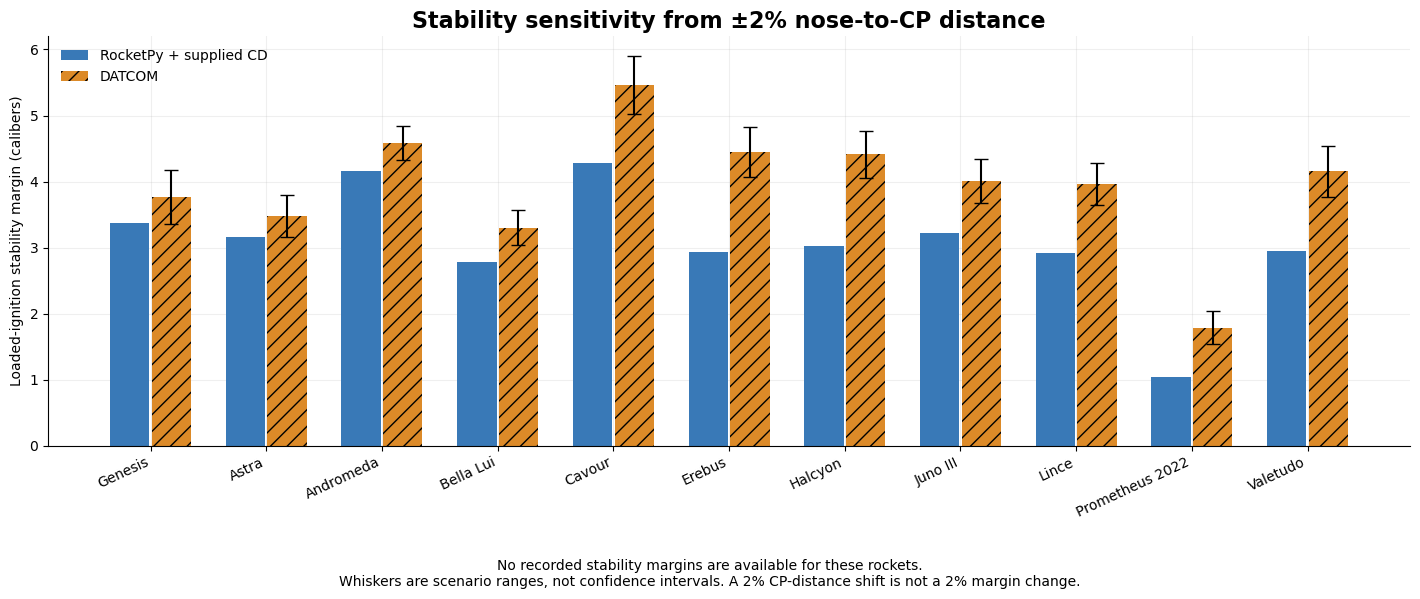

,Rocket,RocketPy (cal),DATCOM (cal),Scenario min (cal),Scenario max (cal),Recorded (cal)
0,genesis,3.377,3.768,3.356,4.180,—
1,astra,3.163,3.477,3.154,3.801,—
2,andromeda,4.159,4.586,4.329,4.842,—
3,bella_lui,2.777,3.304,3.035,3.572,—
4,cavour,4.280,5.465,5.027,5.904,—
5,erebus,2.937,4.450,4.076,4.825,—
6,halcyon,3.019,4.410,4.057,4.763,—
7,juno3,3.221,4.009,3.676,4.341,—
8,lince,2.920,3.963,3.650,4.276,—
9,prometheus_2022,1.042,1.789,1.539,2.039,—


In [10]:
from plot_apogee_uncertainty import plot_stability_comparison

fig = plot_stability_comparison(uncertainty)
save_uncertainty_comparison(fig, DATA, stem="stability_uncertainty_comparison")
plt.show()
plt.close(fig)
show(uncertainty[["rocket", "rocketpy_stability", "datcom_stability", "datcom_stability_low", "datcom_stability_high", "recorded_stability"]].rename(columns={
    "rocket": "Rocket", "rocketpy_stability": "RocketPy (cal)",
    "datcom_stability": "DATCOM (cal)", "datcom_stability_low": "Scenario min (cal)",
    "datcom_stability_high": "Scenario max (cal)", "recorded_stability": "Recorded (cal)",
}))


### Why some DATCOM results are unavailable

These gaps reflect missing inputs or current integration limits. They do not represent zero predicted apogee or a failed accuracy comparison.

| Rocket | Why DATCOM is unavailable |
| --- | --- |
| **Camões** | Its air-brake controller overrides whole-vehicle drag. Coupling it with DATCOM needs an incremental air-brake drag model to avoid double-counting drag. |
| **Defiance** | The fin root centre lies behind the inferred DATCOM body end. The body extent and fin attachment need reconciling before generating a valid model. This does not establish that the real rocket's geometry is invalid. |
| **NDRT 2020** | Its internal diameter transition is followed by another cylindrical body section. The current DATCOM builder supports an aft boattail, rather than this body arrangement. |
| **Hedy** | Required source files under `data/rockets/tust` are missing. Its fin cutout also needs additional geometry support. |
| **Valkyrie** | The source requests live weather, and no archived launch-atmosphere profile is available for a reproducible comparison. |

**Hedy and Valkyrie's RocketPy apogees are archived notebook outputs, not fresh simulations.** Their bars are labelled accordingly. Grey bars indicate that the competing result is unavailable, so no closer/farther ranking is assigned. The same availability limits apply to the trajectory panels below.

Missing data or geometry/controller support must be supplied before adding these DATCOM predictions; silently substituting inputs would change the comparison.

## Peak upward vertical velocity (m/s)

In [4]:
show(metrics[metrics.metric == 'Peak upward vertical velocity'][['rocket', 'measured', 'rocketpy', 'datcom', 'rocketpy_error_pct', 'datcom_error_pct']])

,rocket,measured,rocketpy,datcom,rocketpy_error_pct,datcom_error_pct
1,andromeda,324.109,343.154,352.641,5.876,8.803
6,astra,—,306.480,318.547,—,—
11,bella_lui,90.000,86.176,86.473,-4.249,-3.918
16,camoes,—,327.440,—,—,—
21,cavour,314.000,304.640,319.055,-2.981,1.610
26,defiance,—,438.711,—,—,—
31,erebus,—,294.171,307.317,—,—
36,genesis,—,290.636,299.262,—,—
41,halcyon,—,275.571,280.950,—,—
46,hedy,—,—,—,—,—


## CD and the apogee-fitted effective coefficient

In [5]:
show(metrics[metrics.metric == 'Coast CD at Mach 0.6'][['rocket', 'measured', 'rocketpy', 'datcom', 'inferred_cd', 'rocketpy_vs_fitted_cd_pct', 'datcom_vs_fitted_cd_pct']])

,rocket,measured,rocketpy,datcom,inferred_cd,rocketpy_vs_fitted_cd_pct,datcom_vs_fitted_cd_pct
3,andromeda,—,0.498,0.349,0.591,-15.707,-40.986
8,astra,—,0.654,0.426,0.599,9.168,-28.787
13,bella_lui,—,0.460,0.346,0.446,3.195,-22.431
18,camoes,—,0.704,—,—,—,—
23,cavour,—,0.583,0.448,0.609,-4.214,-26.353
28,defiance,—,0.668,—,0.657,1.606,—
33,erebus,—,0.531,0.376,0.443,19.900,-15.099
38,genesis,—,0.550,0.475,0.609,-9.687,-22.043
43,halcyon,—,0.426,0.319,0.345,23.594,-7.450
48,hedy,—,—,—,—,—,—


## CD comparison curves with uncertainty

Separate powered and coast panels compare **RocketPy's supplied CD curve** (blue) with **nominal DATCOM** (orange) for all 11 supported rockets. Orange bands apply the active **±20% minimum** drag rule at **alpha = beta = 0°**, retaining larger converted Wu discrepancies inside its measured Mach range. These are engineering sensitivity bands, not confidence intervals. The ±2% CP shift does not directly change zero-incidence static CD.

The dotted black line is an **apogee-fitted constant CD**, calibrated in the ordinary RocketPy model to the recorded apogee. It is inferred and nonunique, **not measured CD**. None of the supplied records establishes measured CD, so the chart cannot determine which drag curve is more accurate. The supplied curves are not universally CFD-derived.

Grey backgrounds identify Mach numbers **above the reference ascent peak** (the greater of the two nominal peak Mach values). Curves use the saved native Mach/atmosphere schedules; native values outside the actual input grid are omitted. In particular, large transonic bands beyond the grey boundary need not affect the simulated ascent. These are fixed-incidence curve comparisons, not drag histories along the flight.

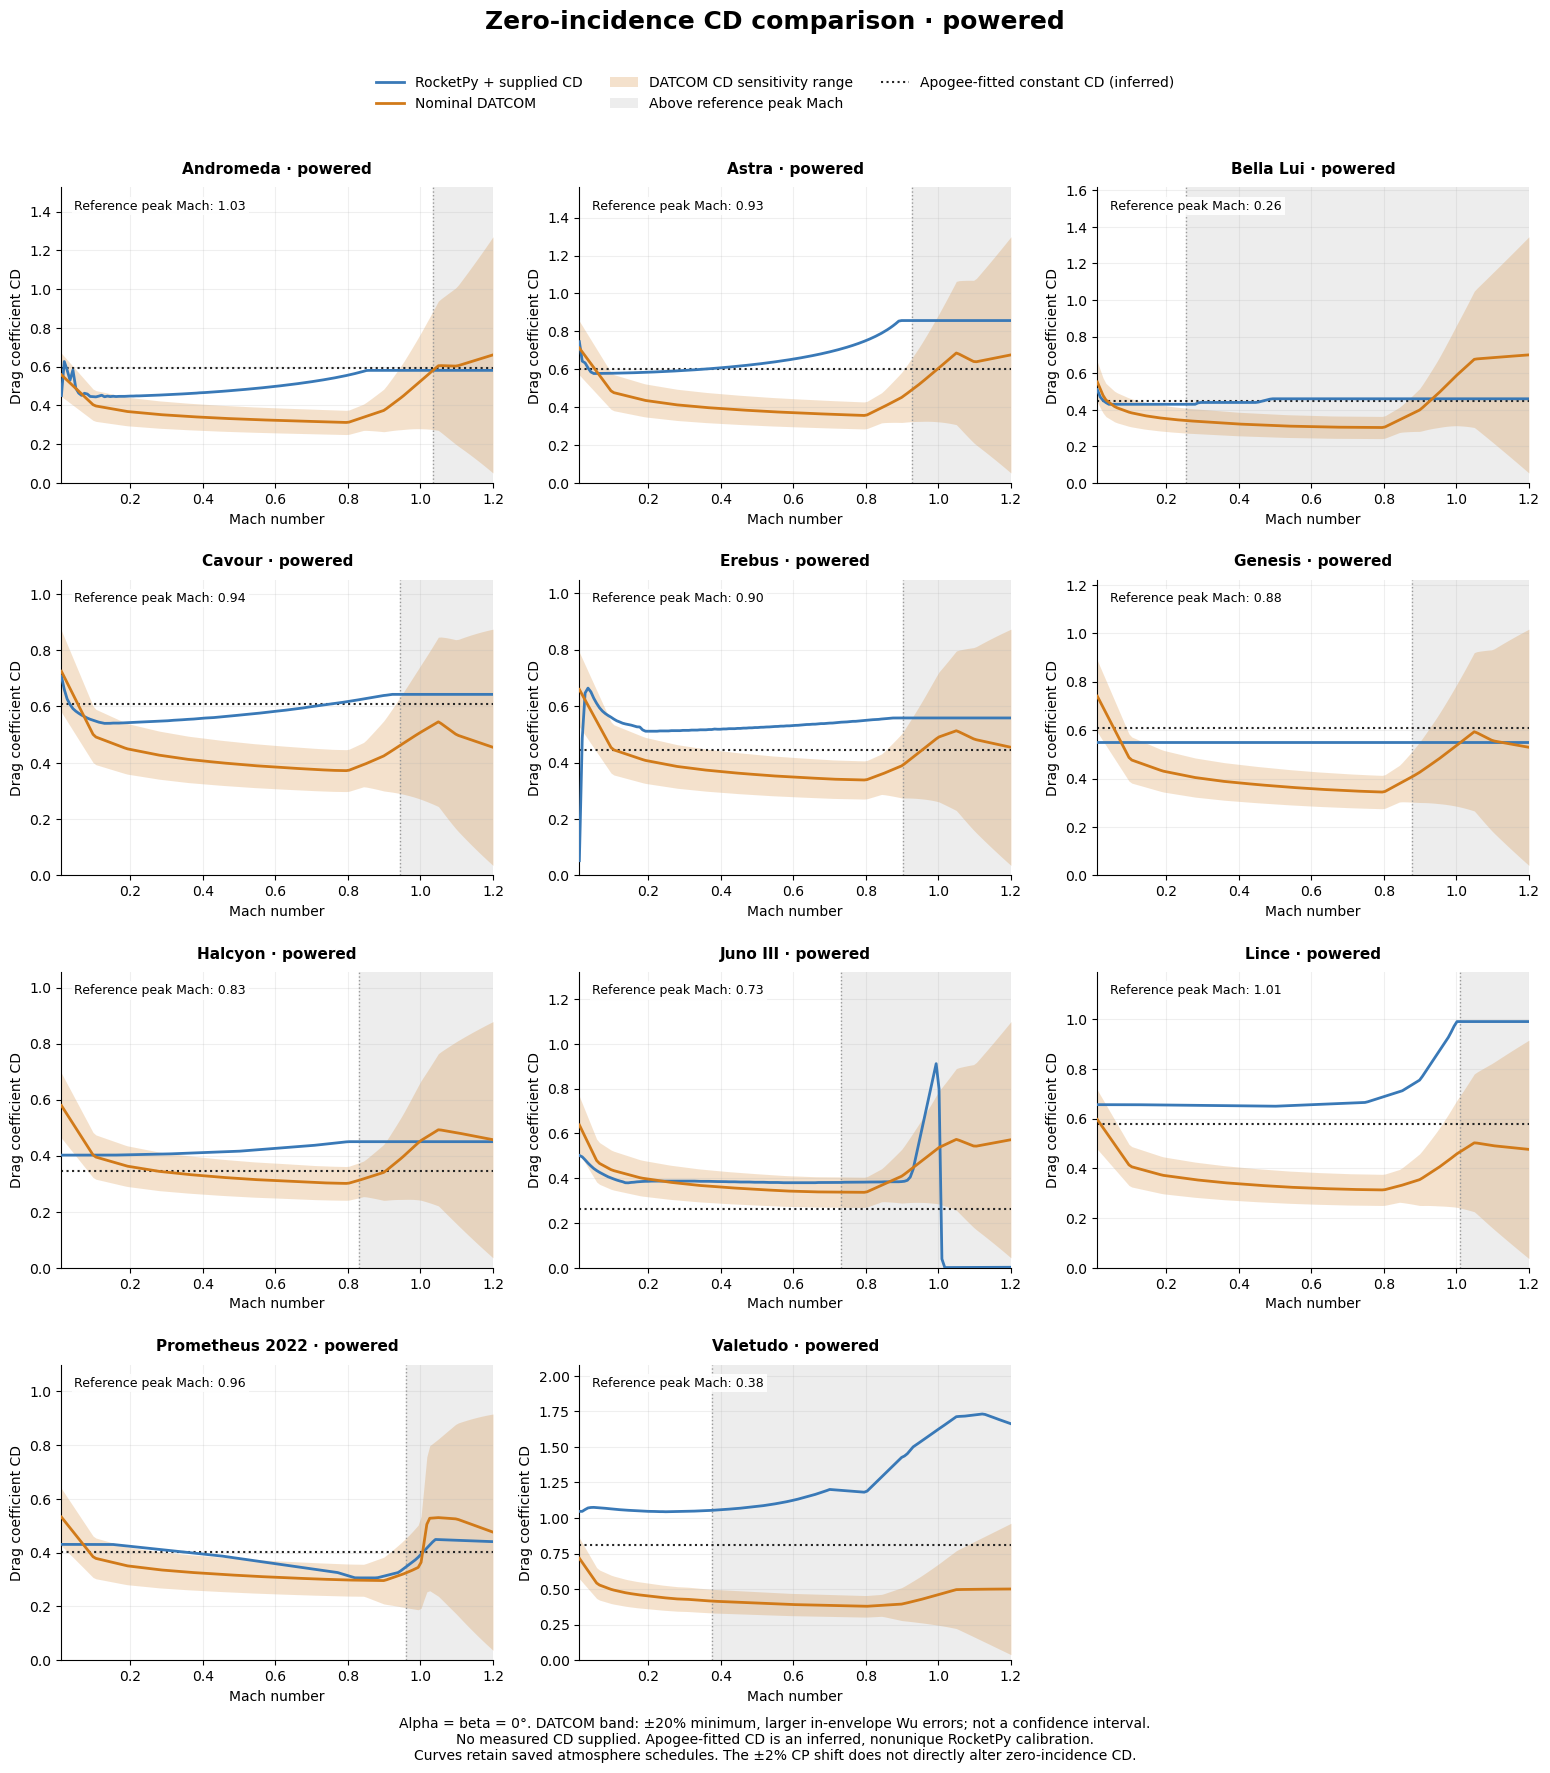

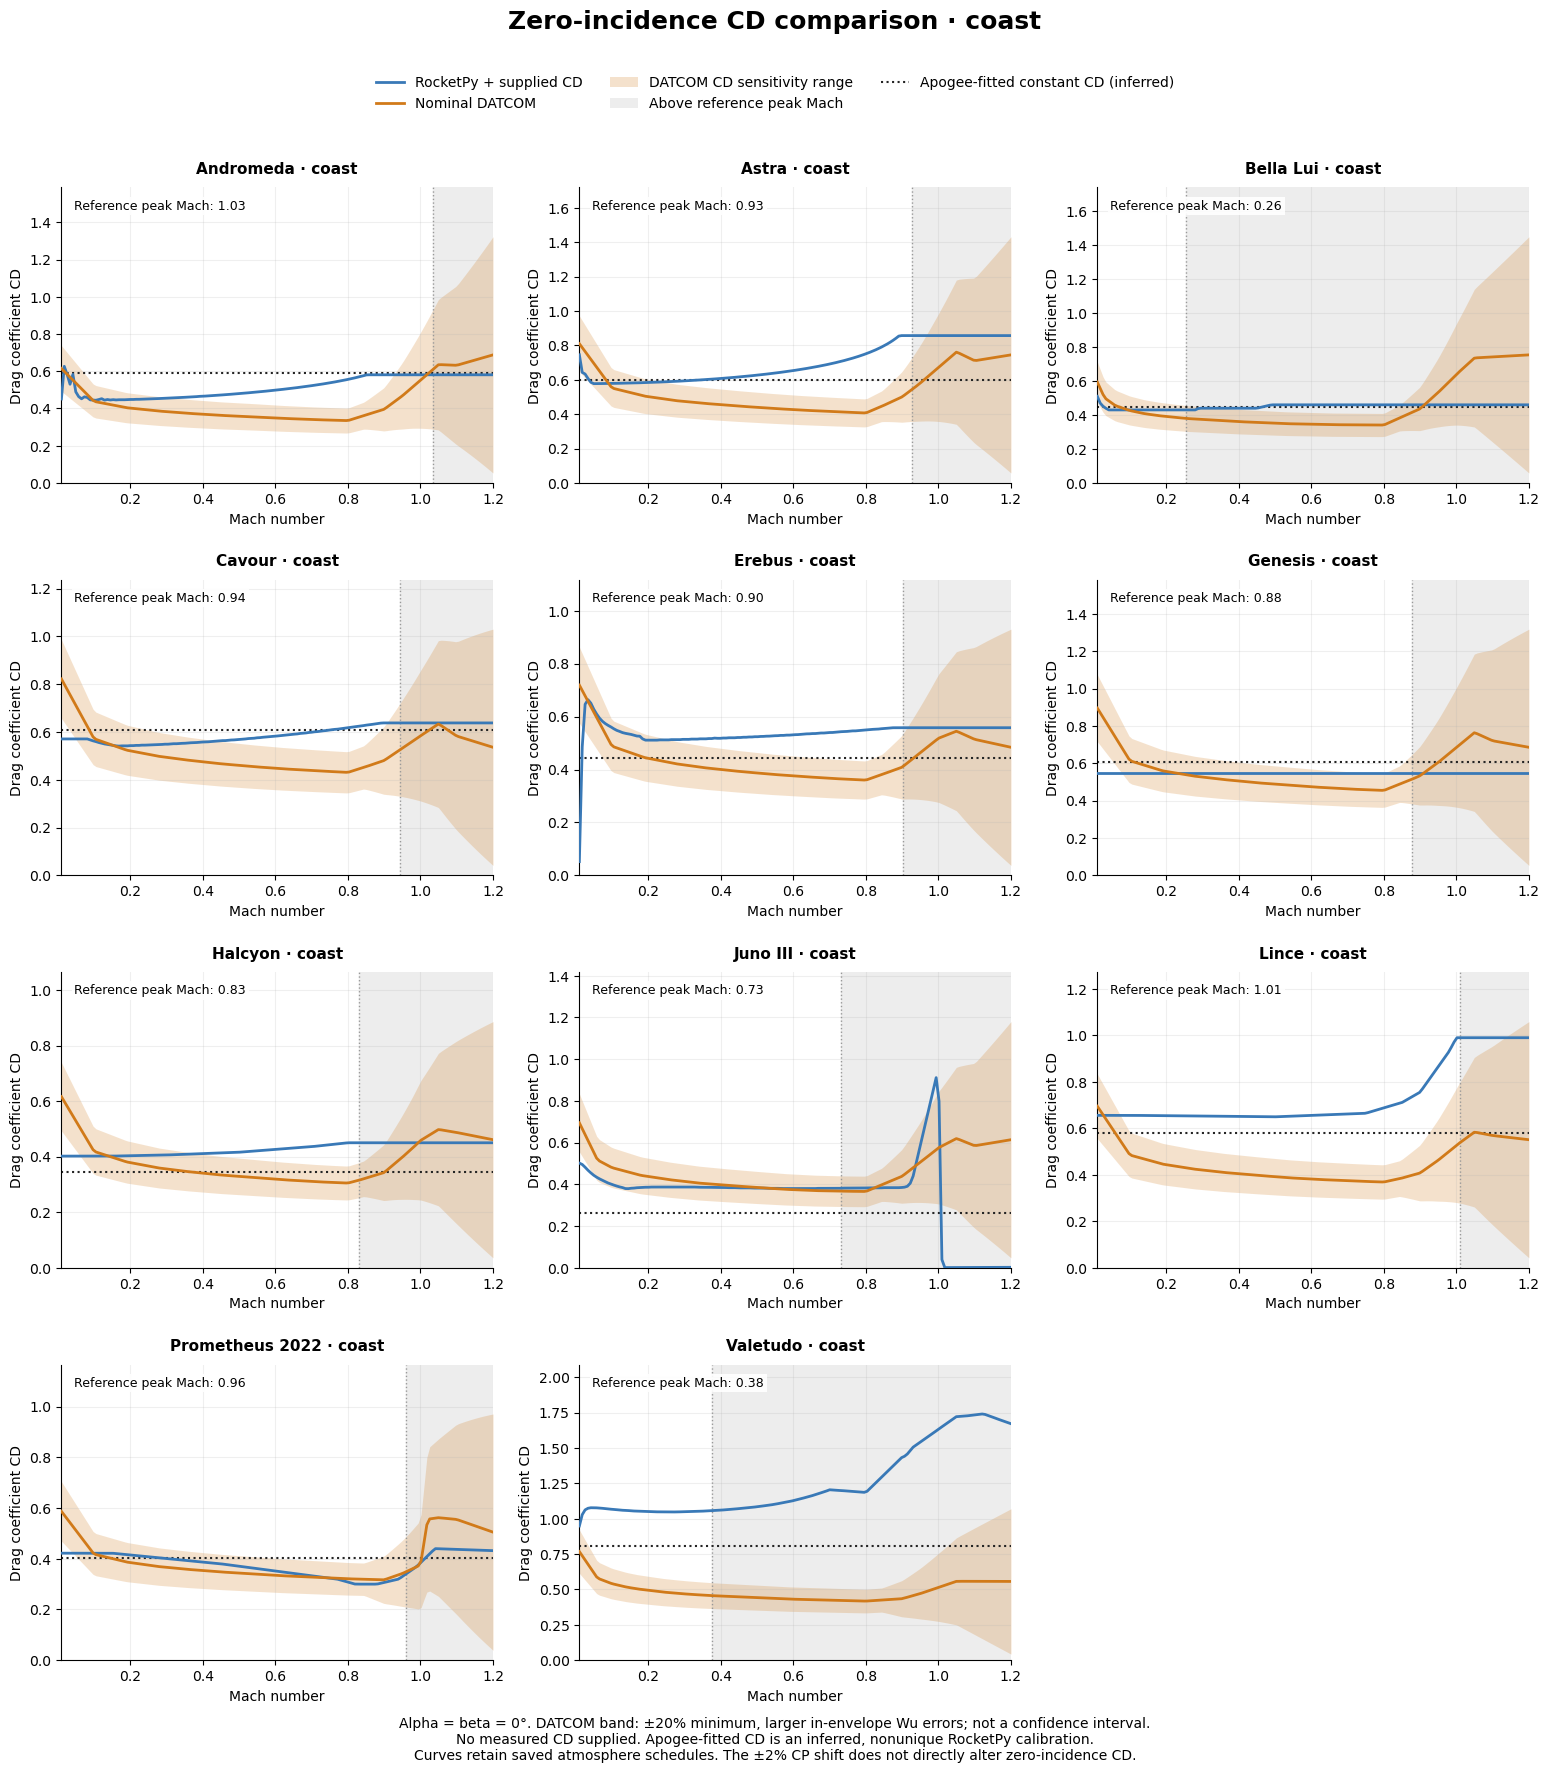

In [11]:
from plot_cd_comparison import cd_comparison_data, plot_cd_comparison, save_cd_comparison

cd_curves = cd_comparison_data(DATA)
cd_curves.to_csv(DATA / "cd_uncertainty_comparison.csv", index=False)
for phase in ("powered", "coast"):
    fig = plot_cd_comparison(cd_curves, phase=phase)
    save_cd_comparison(fig, f"cd_{phase}_comparison", DATA)
    plt.show()
    plt.close(fig)


## Initial static margin (calibers)

In [6]:
show(metrics[metrics.metric == 'Initial static margin'][['rocket', 'measured', 'rocketpy', 'datcom', 'rocketpy_error_pct', 'datcom_error_pct']])

,rocket,measured,rocketpy,datcom,rocketpy_error_pct,datcom_error_pct
2,andromeda,—,4.159,4.586,—,—
7,astra,—,3.163,3.477,—,—
12,bella_lui,—,2.777,3.304,—,—
17,camoes,—,3.762,—,—,—
22,cavour,—,4.280,5.465,—,—
27,defiance,—,7.960,—,—,—
32,erebus,—,2.937,4.450,—,—
37,genesis,—,3.377,3.768,—,—
42,halcyon,—,3.019,4.410,—,—
47,hedy,—,—,—,—,—


## Trajectory, CD and stability comparisons

Blue is ordinary RocketPy; orange is native DATCOM; black is recorded data where available. Dotted CD is the inferred constant needed for the recorded apogee. CD curves are zero-incidence values, not time histories. Stability curves follow each simulated Mach and moving CG; the scalar table uses Mach-zero loaded ignition (DATCOM clamps to its lowest positive Mach). NDRT's recorded stability appears as an annotation because its measurement conditions are unknown.

Recorded altitude keeps its original time and datum. QA flags the two extreme Juno altitude jumps; raw data and masks remain saved. Velocity uses explicitly supplied channels during the QA ascent, without differentiating altitude or fitting a time shift. Reported scalar apogees and telemetry maxima can differ; reported/recovered apogees remain the preferred scalar references.

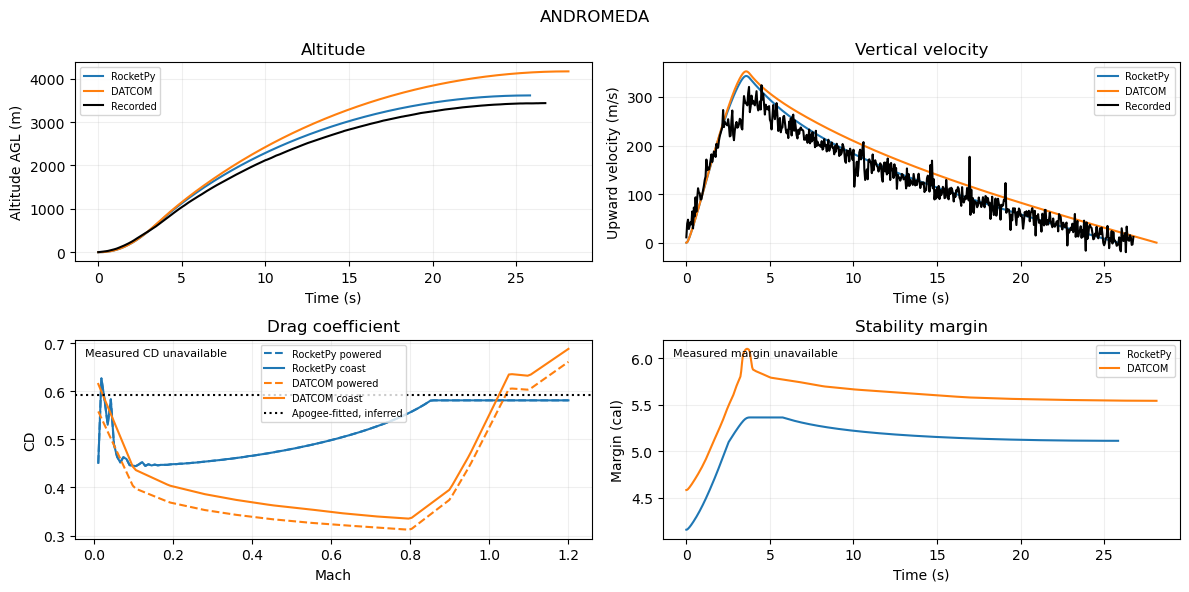

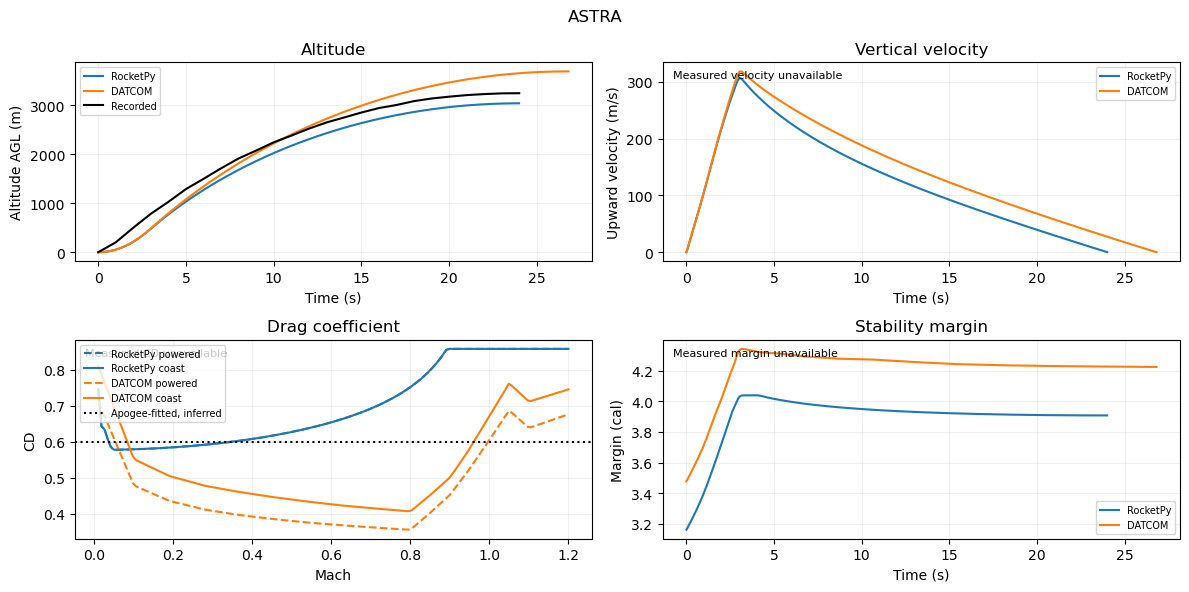

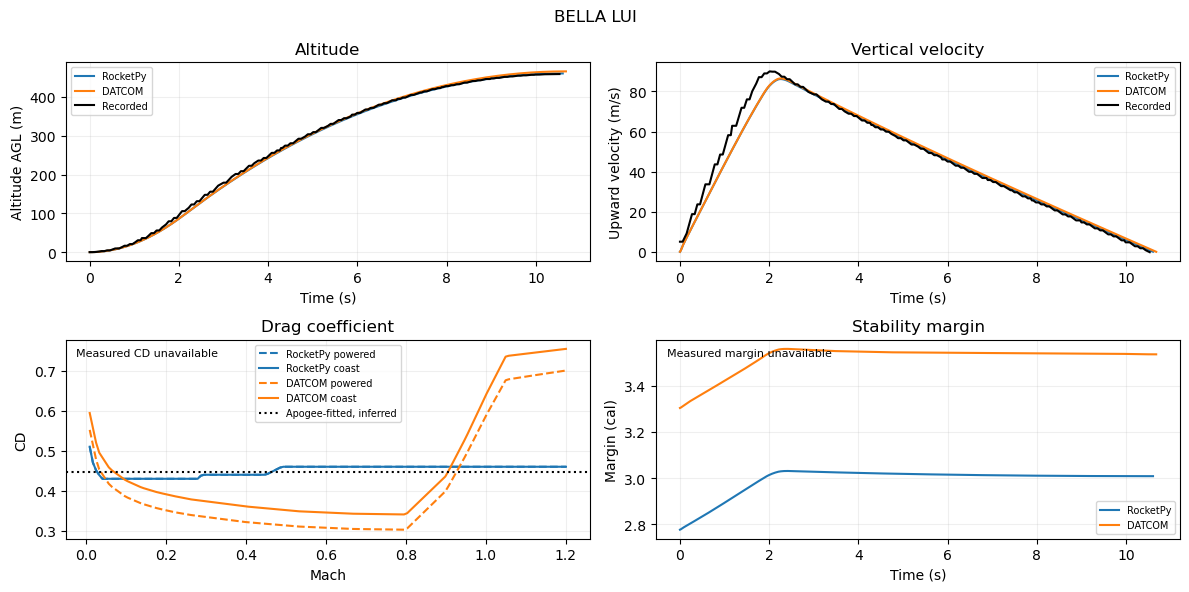

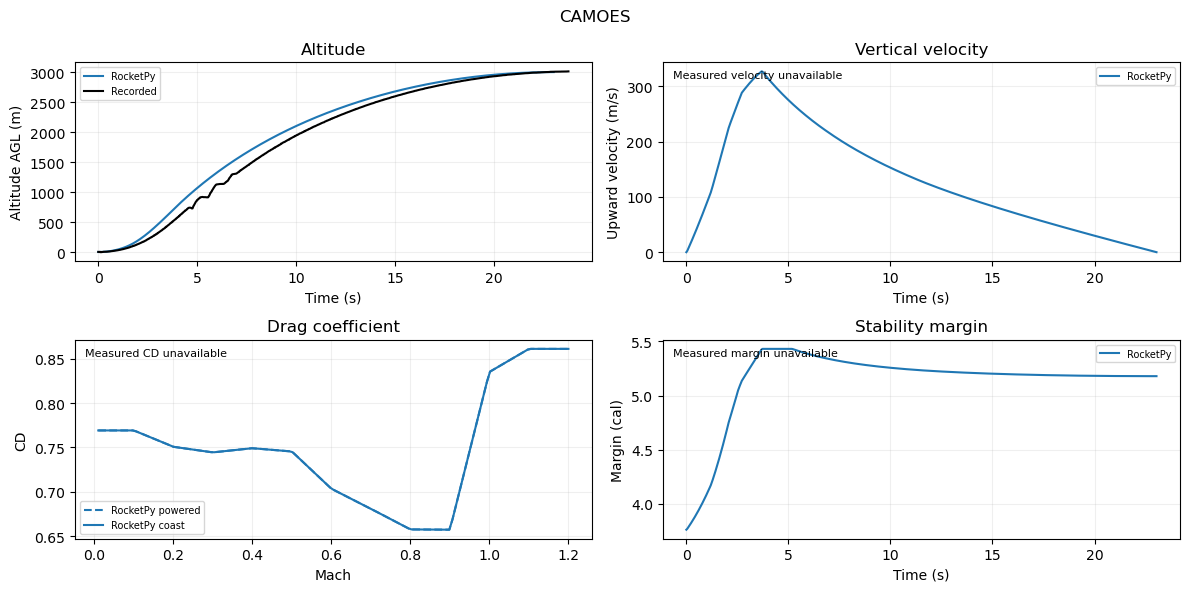

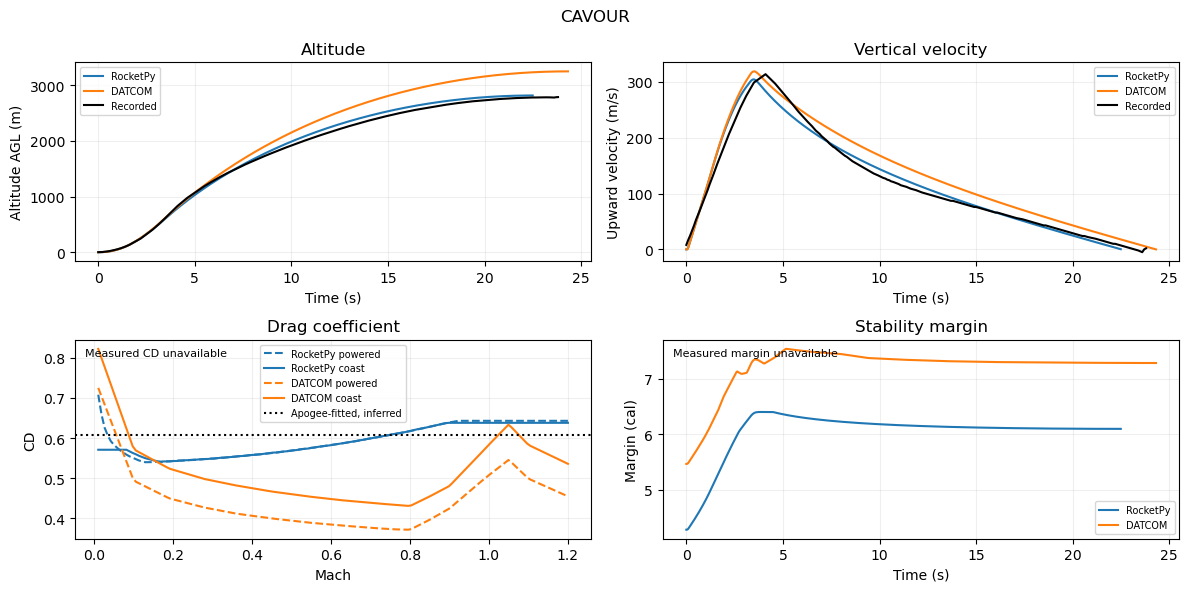

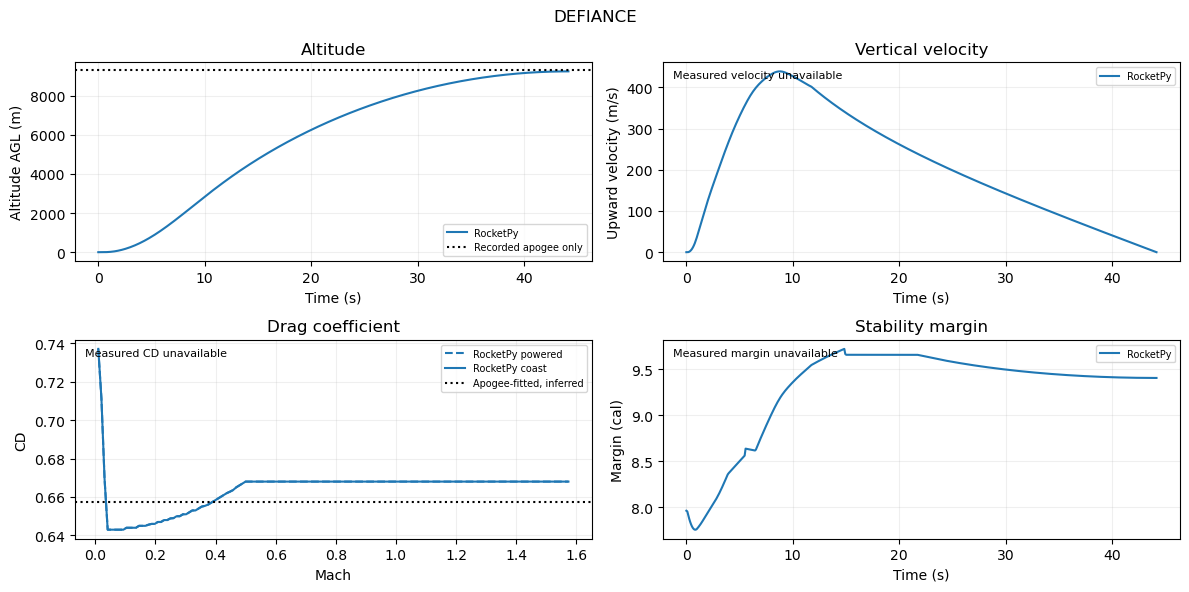

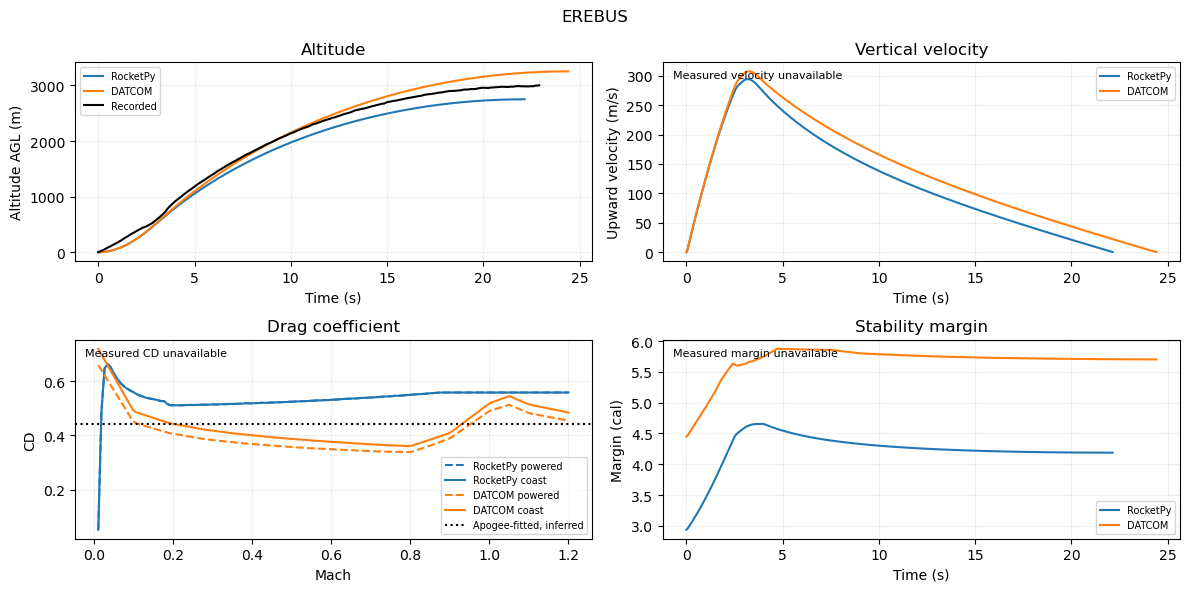

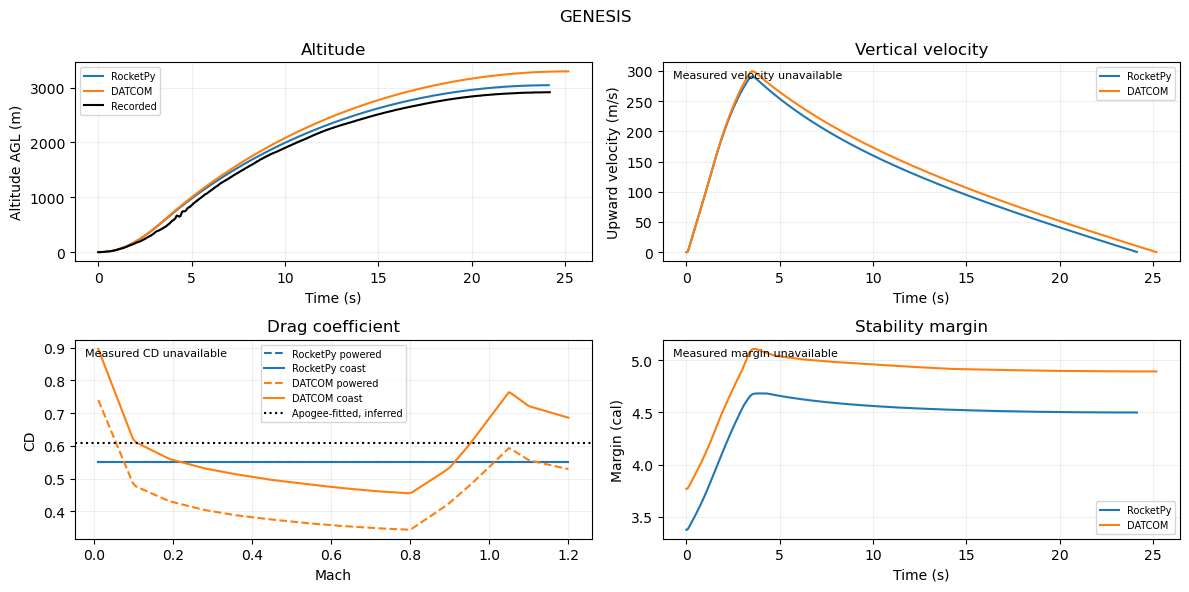

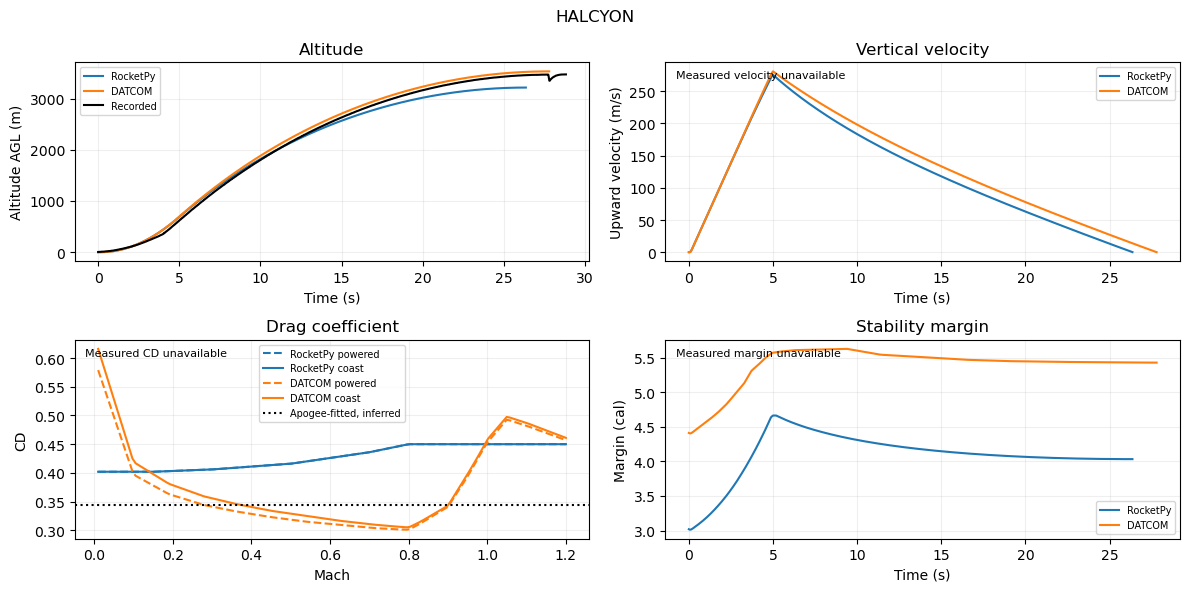

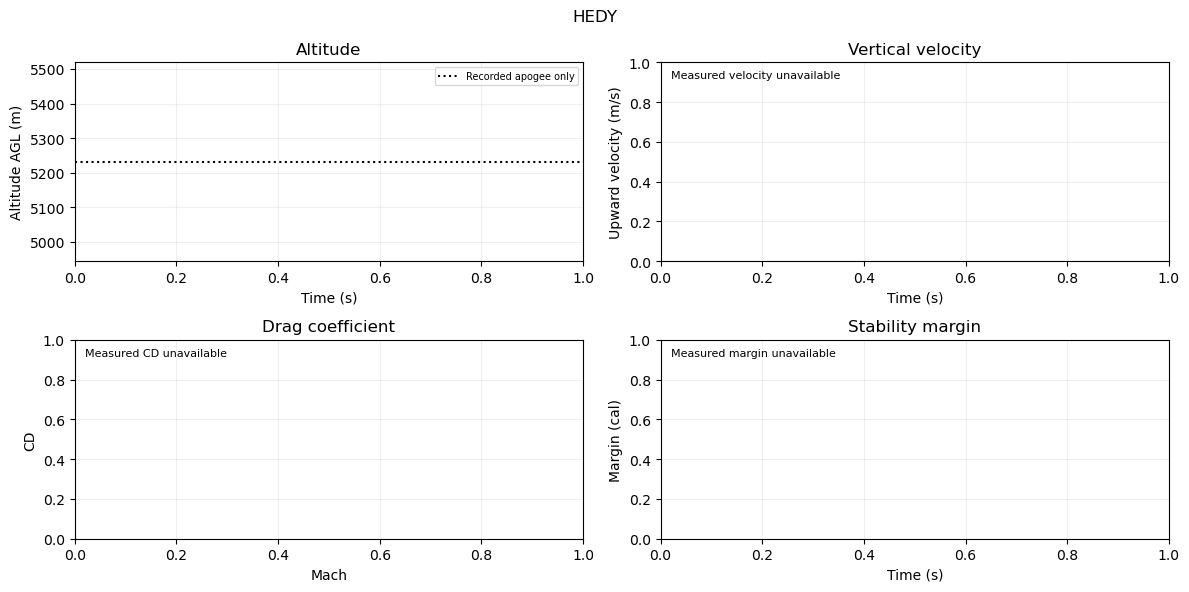

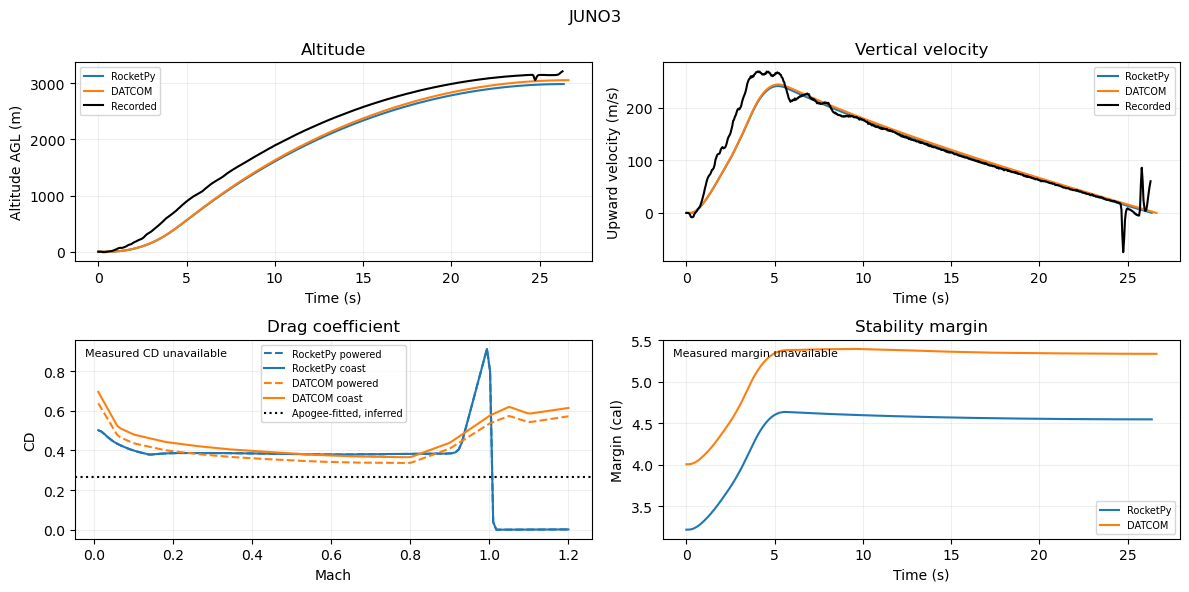

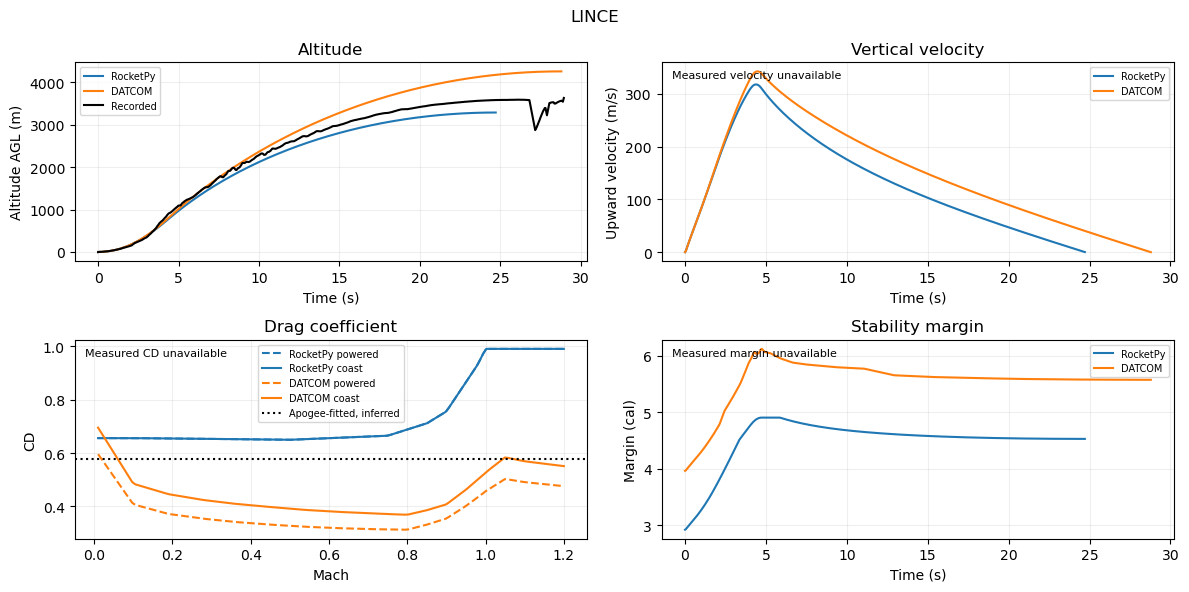

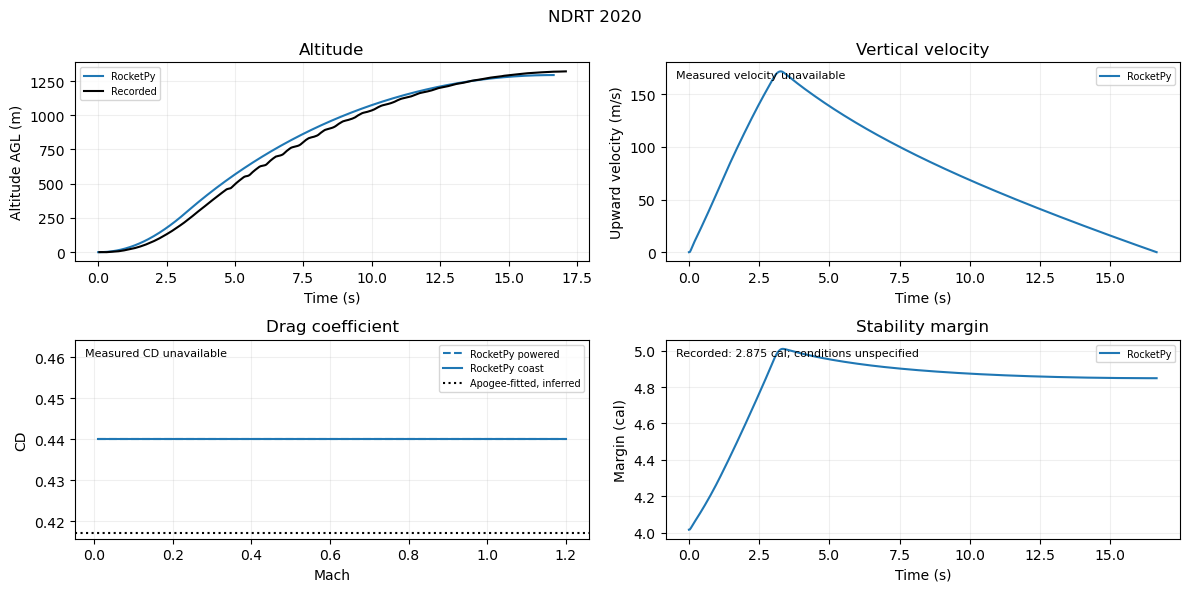

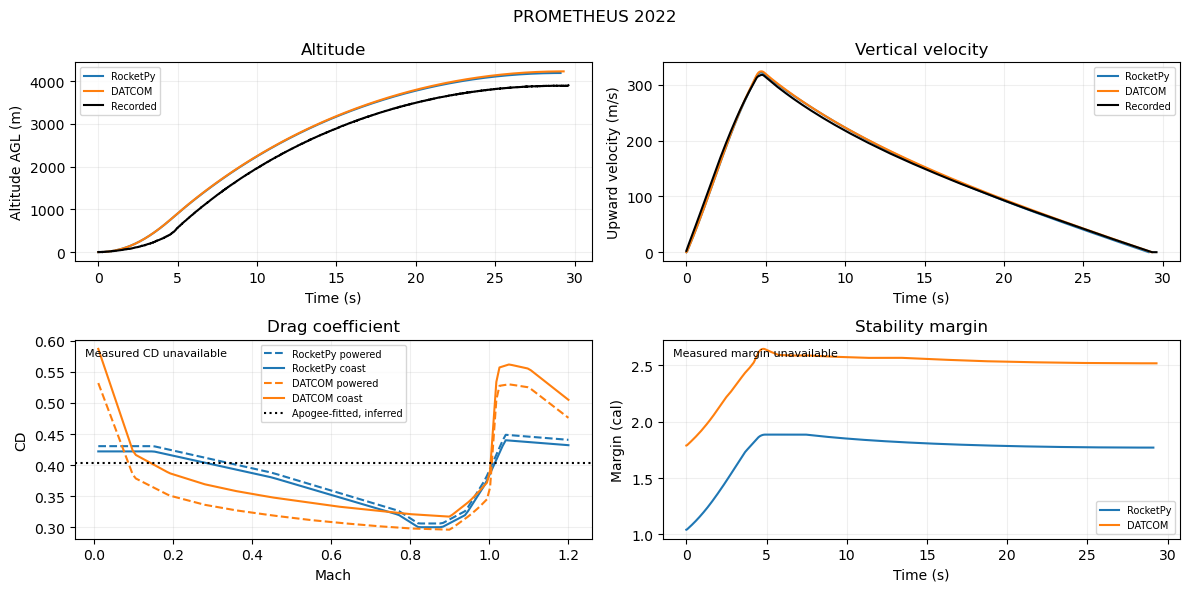

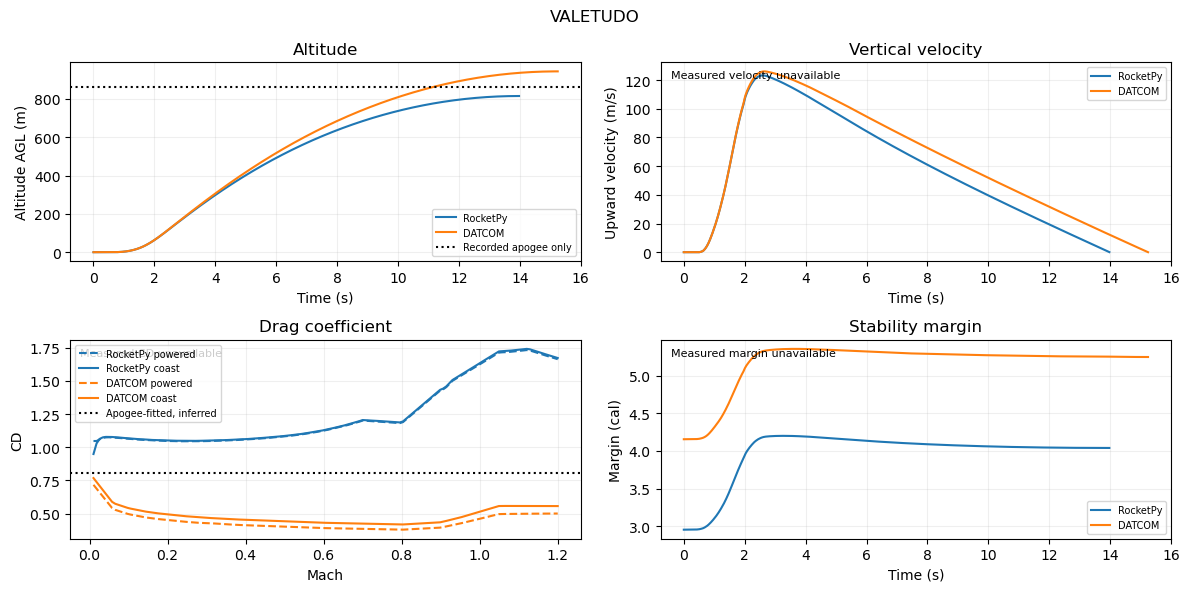

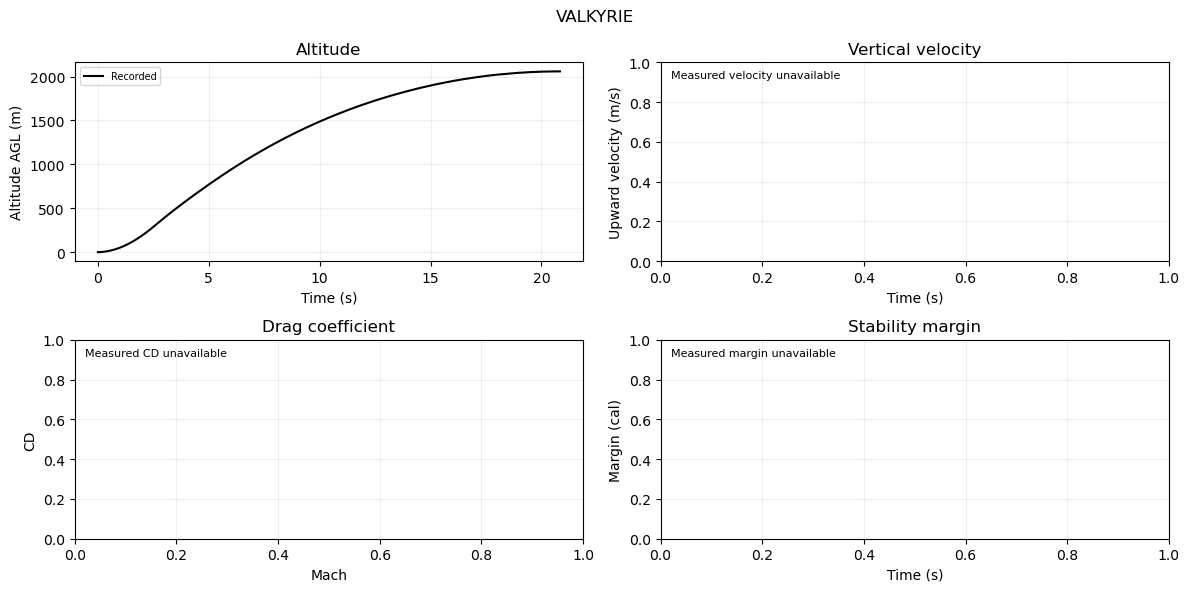

In [7]:
for name in status.rocket:
    fig, axes = plt.subplots(2, 2, figsize=(12, 6))
    history_path = DATA / "rockets" / f"{name}_altitude.csv"
    if history_path.exists():
        history = pd.read_csv(history_path)
        for prefix, label, color in [("ordinary", "RocketPy", "tab:blue"), ("datcom", "DATCOM", "tab:orange")]:
            for axis, suffix in [(axes[0,0], "agl_m"), (axes[0,1], "vz_m_s"), (axes[1,1], "margin_cal")]:
                column = f"{prefix}_{suffix}"
                if column in history:
                    axis.plot(history.time_s, history[column], label=label, color=color)
    measured_path = DATA / "rockets" / f"{name}_telemetry.csv"
    if measured_path.exists():
        measured = pd.read_csv(measured_path)
        measured = measured[measured.qa_valid]
        end = measured.loc[measured.altitude_agl_m.idxmax(), "time_s"]
        measured = measured[(measured.time_s >= 0) & (measured.time_s <= end)]
        axes[0,0].plot(measured.time_s, measured.altitude_agl_m, color="black", label="Recorded")
    else:
        value = metrics[(metrics.rocket==name) & (metrics.metric=="Apogee AGL")].measured.iloc[0]
        axes[0,0].axhline(value, color="black", linestyle=":", label="Recorded apogee only")
    velocity_path = DATA / "rockets" / f"{name}_velocity.csv"
    if velocity_path.exists():
        velocity = pd.read_csv(velocity_path); velocity = velocity[velocity.qa_valid]
        axes[0,1].plot(velocity.time_s, velocity.measured_vz_m_s, color="black", label="Recorded")
    else:
        axes[0,1].text(.02,.96,"Measured velocity unavailable", transform=axes[0,1].transAxes, va="top", fontsize=8)
    cd_path = DATA / "rockets" / f"{name}_cd.csv"
    if cd_path.exists():
        cd = pd.read_csv(cd_path)
        for prefix, label, color in [("rocketpy", "RocketPy", "tab:blue"), ("datcom", "DATCOM", "tab:orange")]:
            for phase, style in [("powered", "--"), ("coast", "-")]:
                column = f"{prefix}_{phase}_cd"
                if column in cd:
                    axes[1,0].plot(cd.mach, cd[column], style, color=color, label=f"{label} {phase}")
    fit = metrics[(metrics.rocket==name) & (metrics.metric=="Apogee-fitted constant CD")]
    if not fit.empty and pd.notna(fit.inferred_cd.iloc[0]):
        axes[1,0].axhline(fit.inferred_cd.iloc[0], color="black", linestyle=":", label="Apogee-fitted, inferred")
    axes[1,0].text(.02,.96,"Measured CD unavailable",transform=axes[1,0].transAxes, va="top", fontsize=8)
    if name == "ndrt_2020":
        axes[1,1].text(.02,.96,"Recorded: 2.875 cal; conditions unspecified", transform=axes[1,1].transAxes, va="top",fontsize=8)
    else:
        axes[1,1].text(.02,.96,"Measured margin unavailable",transform=axes[1,1].transAxes, va="top",fontsize=8)
    for axis,title,xlabel,ylabel in [(axes[0,0],"Altitude","Time (s)","Altitude AGL (m)"), (axes[0,1],"Vertical velocity","Time (s)","Upward velocity (m/s)"), (axes[1,0],"Drag coefficient","Mach","CD"), (axes[1,1],"Stability margin","Time (s)","Margin (cal)")]:
        axis.set(title=title,xlabel=xlabel,ylabel=ylabel)
        if axis.get_legend_handles_labels()[0]: axis.legend(fontsize=7)
    fig.suptitle(name.replace("_"," ").upper())
    fig.tight_layout(); plt.show()


## Availability and calibration residuals

In [8]:
show(status[["rocket", "status", "reason", "notes"]])
show(metrics[metrics.metric=="Apogee-fitted constant CD"][["rocket","inferred_cd","fit_apogee_residual_m","condition"]])
assert metrics[metrics.metric=="Coast CD at Mach 0.6"].measured.isna().all()
fits = metrics[metrics.metric=="Apogee-fitted constant CD"].dropna(subset=["inferred_cd"])
assert (fits.fit_apogee_residual_m.abs() <= .5).all()


,rocket,status,reason,notes
0,andromeda,paired untuned comparison,—,Telemetry maximum 3438.549 m differs from notebook reported value 3443.000 m; both retained.
1,astra,paired untuned comparison,—,Telemetry maximum 3249.460 m differs from notebook reported value 3250.000 m; both retained. | Source fin trailing edge overhangs the nozzle-inferred body base by 1.216 mm. Native DATCOM accepts this; the integration now validates root-chord centre attachment instead of rejecting all overhang. Geometry is unchanged.
2,bella_lui,paired untuned comparison,—,—
3,camoes,ordinary only,Source active air brakes override complete rocket drag. Combining their whole-vehicle CD with DATCOM would double-count base drag; no controlled DATCOM result claimed.,Telemetry maximum 3015.996 m differs from notebook reported value 3015.000 m; both retained.
4,cavour,paired untuned comparison,—,—
5,defiance,ordinary only,ValueError: DATCOM fin root chord centers must lie within the body's axial extent; leading edges must be aft of the nose tip,"Source fin root centre is z=-0.025 m, aft of the tail base z=0.0403 m; native root attachment is outside the declared body."
6,erebus,paired untuned comparison,—,Telemetry maximum 3001.751 m differs from notebook reported value 3020.000 m; both retained.
7,genesis,paired untuned comparison,—,Telemetry maximum 2916.692 m differs from notebook reported value 2916.000 m; both retained.
8,halcyon,paired untuned comparison,—,Telemetry QA flags 5 samples with altitude jumps above 2000 m/s; raw maximum 3470.825 m is retained separately. | Telemetry maximum 3470.825 m differs from notebook reported value 3450.000 m; both retained.
9,hedy,archived comparison only,"Source data/rockets/tust is absent; CoolProp is not installed, and the negative-span fin root cutout requires geometry support.","Referenced telemetry file is absent: data/rockets/tust/cats_tust/filteredDataInfo.csv (cell 24). | Referenced telemetry file is absent: data/rockets/tust/cats_tust/gnssInfo.csv (cell 24). | Referenced telemetry file is absent: data/rockets/tust/cats_tust/flightInfo.csv (cell 24). | Referenced telemetry file is absent: data/rockets/tust/cats_tust/imu.csv (cell 24). | Referenced telemetry file is absent: data/rockets/tust/cats_tust/baro.csv (cell 24). | Hedy end comparison uses simulated ASL 5406.918 m against measured AGL 5231.53 m; saved simulated AGL is 5246.918 m, a 160 m datum discrepancy."


,rocket,inferred_cd,fit_apogee_residual_m,condition
4,andromeda,0.591,0.024,"inferred: single constant CD, same powered/coast, ordinary lateral model"
9,astra,0.599,0.003,"inferred: single constant CD, same powered/coast, ordinary lateral model"
14,bella_lui,0.446,0.005,"inferred: single constant CD, same powered/coast, ordinary lateral model"
19,camoes,—,—,not fitted: active air-brake/controller model
24,cavour,0.609,0.001,"inferred: single constant CD, same powered/coast, ordinary lateral model"
29,defiance,0.657,-0.063,"inferred: single constant CD, same powered/coast, ordinary lateral model"
34,erebus,0.443,-0.011,"inferred: single constant CD, same powered/coast, ordinary lateral model"
39,genesis,0.609,-0.003,"inferred: single constant CD, same powered/coast, ordinary lateral model"
44,halcyon,0.345,0.002,"inferred: single constant CD, same powered/coast, ordinary lateral model"
53,juno3,0.264,-0.000,"inferred: single constant CD, same powered/coast, ordinary lateral model"
